## Introduction

We will use machine learning and deep learning algorithms to predict **stock price trends** and detect **fraudulent transactions** based on historical financial data and transaction features.

For stock prediction, models such as **KNN, Random Forest, XGBoost, and LSTM** will be applied to forecast future price movements and generate buy/sell signals.

For fraud detection, techniques like **Naïve Bayes, AutoEncoders, and anomaly detection methods** will be employed to classify transactions as legitimate or fraudulent.

## Step 1: Problem Statement

**Why do stock prices move in certain patterns, and how can fraudulent transactions be detected in financial data?**

### Details:
- **Objective**:
  1. Develop predictive models to forecast stock price trends.
  2. Detect fraudulent financial transactions using anomaly detection techniques.
- **Use Case**:
  - Assist investors in making data-driven trading decisions.
  - Enable financial institutions to proactively detect and prevent fraud.
- **Target Variables**:
  - **For stocks**: Future price movement, daily returns, buy/sell signals.
  - **For fraud detection**: Transaction class (legitimate or fraudulent).

In [1804]:
# Necessary Libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import glob
import os
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc , mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import optuna
import warnings

warnings.filterwarnings('ignore')



## Step 2: Data Collection & Preparation

Clean and structured data is essential for analysis and modeling.

- **Objective**: Aggregate and preprocess stock and transaction datasets.
- **Datasets**: Yahoo Finance Stocks, Credit Card Fraud dataset.
- **Process**: Load CSVs, add identifiers (Ticker), merge files, handle missing values, create derived features.
- **Outcome**: Cleaned datasets ready for EDA and predictive modeling.

In [1805]:
# Load all CSV files
yahoo_path = "/kaggle/input/datasets/tanavbajaj/yahoo-finance-all-stocks-dataset-daily-update/*.csv"
files = glob.glob(yahoo_path)

df_list = []

for file in files:
    yahoo_df = pd.read_csv(file)
    ticker = os.path.basename(file).replace(".csv", "")
    yahoo_df["Ticker"] = ticker
    df_list.append(yahoo_df)

yahoo_data = pd.concat(df_list, ignore_index=True)
print(yahoo_data.head())

                        Date       Open       High        Low      Close  \
0  2020-03-19 00:00:00-04:00  38.145452  43.867270  38.145452  43.152042   
1  2020-03-20 00:00:00-04:00  42.923174  43.876810  42.913639  42.913639   
2  2020-03-23 00:00:00-04:00  40.052727  40.052727  38.126381  38.145454   
3  2020-03-24 00:00:00-04:00  38.145454  38.145454  37.191818  38.145454   
4  2020-03-25 00:00:00-04:00  38.145456  42.722910  36.238183  39.108627   

   Volume  Dividends  Stock Splits Ticker  
0    7000        0.0           0.0   OTIS  
1    3600        0.0           0.0   OTIS  
2   11900        0.0           0.0   OTIS  
3   77800        0.0           0.0   OTIS  
4    7000        0.0           0.0   OTIS  


In [1806]:
fraud_path = "/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv"
fraud_data = pd.read_csv(fraud_path)

print(fraud_data["Class"].value_counts())
print(fraud_data.head())

Class
0    284315
1       492
Name: count, dtype: int64
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458 

In [1807]:
# Load all CSV files
crypto_path = "/kaggle/input/datasets/anasshahid88/crypto-market-data/**/*.csv"
files = glob.glob(crypto_path, recursive=True)
df_list = []

for file in files:
    crypto_df = pd.read_csv(file, parse_dates=["Date"])
    ticker = os.path.basename(file).replace(".csv", "")
    crypto_df["Ticker"] = ticker
    df_list.append(crypto_df)
crypto_df = pd.concat(df_list, ignore_index=True)
print(crypto_df.head())

           Date      Open      High       Low     Close          Volume  \
0  May 07, 2018  9,645.67  9,665.85  9,231.53  9,373.01   7,394,020,000   
1  May 06, 2018  9,845.31  9,940.14  9,465.25  9,654.80   7,222,280,000   
2  May 05, 2018  9,700.28  9,964.50  9,695.12  9,858.15   7,651,940,000   
3  May 04, 2018  9,695.50  9,779.20  9,585.96  9,700.76   8,217,830,000   
4  May 03, 2018  9,233.97  9,798.33  9,188.15  9,743.86  10,207,300,000   

        Market Cap                  Ticker  
0  164,161,000,000  CoinMarketData-bitcoin  
1  167,541,000,000  CoinMarketData-bitcoin  
2  165,055,000,000  CoinMarketData-bitcoin  
3  164,956,000,000  CoinMarketData-bitcoin  
4  157,087,000,000  CoinMarketData-bitcoin  


## Step 3: Exploratory Data Analysis (EDA)

### Part A: Yahoo Finance Stocks EDA

In [1808]:
yahoo_data.shape

(4208047, 9)

In [1809]:
yahoo_data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends',
       'Stock Splits', 'Ticker'],
      dtype='object')

In [1810]:
yahoo_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4208047 entries, 0 to 4208046
Data columns (total 9 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Date          object 
 1   Open          float64
 2   High          float64
 3   Low           float64
 4   Close         float64
 5   Volume        int64  
 6   Dividends     float64
 7   Stock Splits  float64
 8   Ticker        object 
dtypes: float64(6), int64(1), object(2)
memory usage: 288.9+ MB


In [1811]:
yahoo_data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06,4.208047e+06
mean,4.441393e+01,4.504356e+01,4.397453e+01,4.452156e+01,5.289525e+06,3.318746e-03,7.176755e-04
std,1.251266e+02,1.266407e+02,1.235601e+02,1.251297e+02,2.858712e+07,9.130420e-02,4.845057e-02
min,0.000000e+00,1.677443e-03,1.677444e-03,1.708315e-03,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.050718e+00,4.227751e+00,4.113196e+00,4.173002e+00,4.655000e+05,0.000000e+00,0.000000e+00
50%,1.677780e+01,1.703905e+01,1.655592e+01,1.680335e+01,1.384800e+06,0.000000e+00,0.000000e+00
75%,4.464000e+01,4.514003e+01,4.412500e+01,4.464344e+01,3.670228e+06,0.000000e+00,0.000000e+00
max,6.490260e+03,6.525000e+03,6.405000e+03,6.509350e+03,7.421641e+09,1.037500e+02,5.000000e+01


In [1812]:
yahoo_data.isna().sum().sum()

np.int64(0)

In [1813]:
yahoo_data.duplicated().sum()

np.int64(0)

In [1814]:
yahoo_data['Date'] = pd.to_datetime(yahoo_data['Date'], utc=True)
yahoo_data['Date'] = yahoo_data['Date'].dt.tz_convert(None)

yahoo_data = yahoo_data.sort_values('Date')

yahoo_data['Year'] = yahoo_data['Date'].dt.year
year_counts = yahoo_data['Year'].value_counts().sort_index()

In [1815]:
# plt.figure(figsize=(12,5))
# year_counts.plot(kind='line', marker='o')
# plt.title("Number of Records per Year")
# plt.xlabel("Year")
# plt.ylabel("Count")
# plt.grid(True)
# plt.show()

In [1816]:
# daily_close = yahoo_data.groupby('Date')['Close'].mean()

# plt.figure(figsize=(12,6))
# daily_close.plot()
# plt.title("Average Closing Price Over Time")
# plt.xlabel("Date")
# plt.ylabel("Average Close Price")
# plt.grid(True)
# plt.show()

In [1817]:
# yahoo_data['MA20'] = yahoo_data['Close'].rolling(20).mean()

# plt.figure(figsize=(12,5))
# plt.plot(yahoo_data['Date'], yahoo_data['Close'], label='Close Price')
# plt.plot(yahoo_data['Date'], yahoo_data['MA20'], label='20 Day Moving Avg', color='red')
# plt.legend()
# plt.title("Stock Price with Moving Average")
# plt.show()

In [1818]:
# yahoo_data['price_range'] = yahoo_data['High'] - yahoo_data['Low']

# fig, axes = plt.subplots(1, 2, figsize=(12,5))

# axes[0].boxplot(yahoo_data['price_range'])
# axes[0].set_title("Price Range Boxplot")

# Q1 = yahoo_data['price_range'].quantile(0.25)
# Q3 = yahoo_data['price_range'].quantile(0.75)
# IQR = Q3 - Q1

# outliers = yahoo_data[(yahoo_data['price_range'] < Q1 - 1.5*IQR) |
#                       (yahoo_data['price_range'] > Q3 + 1.5*IQR)]

# normal = len(yahoo_data) - len(outliers)

# axes[1].bar(['Normal','Outliers'], [normal, len(outliers)], color='pink')
# axes[1].set_title("Outliers using IQR")

# plt.tight_layout()
# plt.show()

# outlier_pct = (len(outliers) / len(yahoo_data)) * 100
# print(f"Total Outliers: {len(outliers)} ({outlier_pct:.2f}%)")

In [1819]:
# num_yahoo_cols = yahoo_data.select_dtypes(include=['float64','int64']).columns

# fig, axes = plt.subplots(len(num_yahoo_cols), 2, figsize=(12, 5*len(num_yahoo_cols)))

# for i, col in enumerate(num_yahoo_cols):
#     sns.histplot(yahoo_data[col], kde=True, ax=axes[i,0], color='skyblue')
#     axes[i,0].set_title(f"{col} Distribution")

#     sns.boxplot(x=yahoo_data[col], ax=axes[i,1], color='pink')
#     axes[i,1].set_title(f"{col} Boxplot")

# plt.tight_layout()
# plt.show()

In [1820]:
# corr = yahoo_data[num_yahoo_cols].corr()

# plt.figure(figsize=(9, 7))
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
#             mask=mask, linewidths=0.5, square=True,
#             cbar_kws={'shrink': 0.8})
# plt.title('Stocks Feature Correlation Matrix', fontsize=13)
# plt.tight_layout()
# plt.show()

### Part B: Credit Card Fraud EDA

In [1821]:
fraud_data.shape

(284807, 31)

In [1822]:
fraud_data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [1823]:
fraud_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [1824]:
fraud_data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [1825]:
fraud_data.isna().sum().sum()

np.int64(0)

In [1826]:
fraud_data.duplicated().sum()

np.int64(1081)

In [1827]:
# counts = fraud_data['Class'].value_counts()

# plt.figure(figsize=(6,6))
# plt.pie(counts,
#         labels=['Not Fraud', 'Fraud'],
#         autopct='%1.2f%%',
#         startangle=90,
#         colors=['#B0E0E6', '#FFC0CB'])
# plt.title("Fraud vs Non-Fraud Distribution")
# plt.show()

In [1828]:
# num_cols = fraud_data.select_dtypes(include=['int64','float64']).columns

# fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 5*len(num_cols)))

# for i, col in enumerate(num_cols):
#     sns.histplot(fraud_data[col], kde=True, ax=axes[i,0], color='skyblue')
#     axes[i,0].set_title(f"{col} Distribution")

#     sns.boxplot(x=fraud_data[col], ax=axes[i,1], color='pink')
#     axes[i,1].set_title(f"{col} Boxplot")

# plt.tight_layout()
# plt.show()

In [1829]:
# corr = fraud_data.corr()

# plt.figure(figsize=(12,10))
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, annot=False, cmap='coolwarm', mask=mask, linewidths=0.5)
# plt.title("Fraud Dataset Correlation Matrix")
# plt.tight_layout()
# plt.show()

In [1830]:
# plt.figure(figsize=(7,5))
# sns.boxplot(x='Class', y='Amount', data=fraud_data)
# plt.title("Transaction Amount vs Class")
# plt.xlabel("Class (0 = Normal, 1 = Fraud)")
# plt.ylabel("Amount")
# plt.show()

### Part C: Crypto Market EDA

In [1831]:
crypto_df.shape

(13453, 8)

In [1832]:
crypto_df.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Market Cap',
       'Ticker'],
      dtype='object')

In [1833]:
crypto_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13453 entries, 0 to 13452
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Date        13453 non-null  object
 1   Open        13453 non-null  object
 2   High        13453 non-null  object
 3   Low         13453 non-null  object
 4   Close       13453 non-null  object
 5   Volume      13453 non-null  object
 6   Market Cap  13453 non-null  object
 7   Ticker      13453 non-null  object
dtypes: object(8)
memory usage: 840.9+ KB


In [1834]:
crypto_df.describe()

,Date,Open,High,Low,Close,Volume,Market Cap,Ticker
count,13453,13453.000000,13453.000000,13453.000000,13453.000000,13453,13453,13453
unique,1833,9872.000000,9931.000000,9816.000000,9919.000000,12614,13325,14
top,"Apr 06, 2018",0.000014,0.000016,0.000012,0.000014,-,-,CoinMarketData-bitcoin
freq,14,68.000000,62.000000,93.000000,67.000000,625,79,1833


In [1835]:
crypto_df.isna().sum().sum()

np.int64(0)

In [1836]:
crypto_df.duplicated().sum()

np.int64(0)

In [1837]:
# crypto_df['Ticker'].value_counts()

# crypto_df['Ticker'].value_counts().plot(kind='bar', figsize=(10,5))
# plt.title("Number of Records per Cryptocurrency")
# plt.show()

In [1838]:
# crypto_df['Close'].hist(bins=50)
# plt.title("Distribution of Closing Prices")
# plt.show()

In [1839]:
# crypto_df["Market Cap"] = pd.to_numeric(crypto_df["Market Cap"].str.replace(",", ""))
# crypto_df.groupby("Ticker")["Market Cap"].mean().sort_values().plot(kind='barh')
# plt.title("Average Market Cap per Cryptocurrency")
# plt.show()

In [1840]:
# crypto_df["Volume"] = pd.to_numeric(crypto_df["Volume"].str.replace(",", ""))

# crypto_df.groupby("Ticker")["Volume"].mean().sort_values().plot(kind='bar')
# plt.title("Average Trading Volume")
# plt.show()

In [1841]:
# crypto_df['Volatility'] = crypto_df['High'] - crypto_df['Low']

# crypto_df.groupby("Ticker")['Volatility'].mean().sort_values().plot(kind='bar')
# plt.title("Average Volatility per Cryptocurrency")
# plt.show()

In [1842]:
# crypto_df['Date'] = pd.to_datetime(crypto_df['Date'], format='mixed')
# crypto_df['Year'] = crypto_df['Date'].dt.year

In [1843]:
# crypto_df.groupby('Year').size().plot(kind='bar')
# plt.title("Records per Year")
# plt.show()

In [1844]:
# crypto_df.groupby('Year')['Market Cap'].mean().plot()
# plt.title("Market Cap Growth Over Years")
# plt.show()

In [1845]:
# crypto_df['Daily_Return'] = crypto_df['Close'].pct_change()

# crypto_df['Daily_Return'].hist(bins=100)
# plt.title("Daily Return Distribution")
# plt.show()

In [1846]:
# crypto_df['price_range'] = crypto_df['High'] - crypto_df['Low']

# fig, axes = plt.subplots(1, 2, figsize=(12,5))

# axes[0].boxplot(crypto_df['price_range'])
# axes[0].set_title("Price Range Boxplot")

# Q1 = crypto_df['price_range'].quantile(0.25)
# Q3 = crypto_df['price_range'].quantile(0.75)
# IQR = Q3 - Q1

# outliers = crypto_df[(crypto_df['price_range'] < Q1 - 1.5*IQR) |
#                      (crypto_df['price_range'] > Q3 + 1.5*IQR)]

# normal = len(crypto_df) - len(outliers)

# axes[1].bar(['Normal','Outliers'], [normal, len(outliers)], color='pink')
# axes[1].set_title("Outliers using IQR")

# plt.tight_layout()
# plt.show()

# outlier_pct = (len(outliers) / len(crypto_df)) * 100
# print(f"Total Outliers: {len(outliers)} ({outlier_pct:.2f}%)")

In [1847]:
# num_cols = crypto_df.select_dtypes(include=['int64','float64']).columns

# fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 5*len(num_cols)))

# for i, col in enumerate(num_cols):
#     sns.histplot(crypto_df[col], kde=True, ax=axes[i,0], color='skyblue')
#     axes[i,0].set_title(f"{col} Distribution")

#     sns.boxplot(x=crypto_df[col], ax=axes[i,1], color='pink')
#     axes[i,1].set_title(f"{col} Boxplot")

# plt.tight_layout()
# plt.show()

In [1848]:
# corr = crypto_df[['Open','High','Low','Close','Volume','Market Cap']].corr()

# plt.figure(figsize=(8,6))
# sns.heatmap(corr, annot=True, cmap='coolwarm')
# plt.title("Feature Correlation Heatmap")
# plt.show()

## Step 4: Preprocessing

In [1849]:
def calc_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

In [1850]:
def calc_macd(data, slow=26, fast=12, signal=9):
    ema_fast = data.ewm(span=fast, adjust=False).mean()
    ema_slow = data.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    macd_histogram = macd_line - signal_line
    return macd_line, signal_line, macd_histogram

In [1851]:
def calc_atr(high, low, close, window=14):
    tr1 = high - low
    tr2 = (high - close.shift()).abs()
    tr3 = (low - close.shift()).abs()
    true_range = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = true_range.rolling(window=window).mean()
    return atr

### Part A: Yahoo Finance Stocks

In [1852]:
if 'Date' in yahoo_data.columns:
    yahoo_data['Date'] = pd.to_datetime(yahoo_data['Date'])
    yahoo_data.set_index('Date', inplace=True)
yahoo_data.sort_index(inplace=True)

yahoo_data['Target'] = (yahoo_data['Close'].shift(-1) > yahoo_data['Close']).astype(int)

yahoo_data.dropna(inplace=True)

In [1853]:
yahoo_data['Daily_Return'] = yahoo_data['Close'].pct_change()
yahoo_data['Price_Range_Pct'] = (yahoo_data['High'] - yahoo_data['Low']) / yahoo_data['Close'] * 100

In [1854]:
yahoo_data['RSI'] = calc_rsi(yahoo_data['Close'])
macd_line, macd_signal, macd_hist = calc_macd(yahoo_data['Close'])
yahoo_data['MACD_Line'], yahoo_data['MACD_Signal'], yahoo_data['MACD_Hist'] = macd_line, macd_signal, macd_hist
yahoo_data['ATR'] = calc_atr(yahoo_data['High'], yahoo_data['Low'], yahoo_data['Close'])

In [1855]:
for w in [5,10,20]:
    yahoo_data[f'SMA_{w}'] = yahoo_data['Close'].rolling(w).mean()
    yahoo_data[f'EMA_{w}'] = yahoo_data['Close'].ewm(span=w, adjust=False).mean()

In [1856]:
num_yahoo_cols = yahoo_data.select_dtypes(include=['float64','int64']).columns.drop('Target')

for col in num_yahoo_cols:
    mean = yahoo_data[col].mean()
    std = yahoo_data[col].std()
    yahoo_data = yahoo_data[(yahoo_data[col] >= mean - 3*std) & (yahoo_data[col] <= mean + 3*std)]

### Part B: Credit Card Fraud

In [1857]:
fraud_data = fraud_data.drop_duplicates()
print(f"After removing duplicates: {fraud_data.shape}")

dist = fraud_data['Class'].value_counts(normalize=True) * 100
print(f"Class distribution:\n{dist.to_string()}")

After removing duplicates: (283726, 31)
Class distribution:
Class
0    99.83329
1     0.16671


In [1858]:
fraud_data['Amount_Log'] = np.log1p(fraud_data['Amount'])
fraud_data['Amount_Scaled_By_Time'] = fraud_data['Amount'] / (fraud_data['Time'] + 1)

### Part C: Crypto Market

In [1859]:
if 'Date' in crypto_df.columns:
    crypto_df['Date'] = pd.to_datetime(crypto_df['Date'], format='mixed')
    crypto_df.set_index('Date', inplace=True)

crypto_df.sort_index(inplace=True)

crypto_df['Close'] = crypto_df['Close'].astype(str).str.replace(',', '')
crypto_df['Close'] = pd.to_numeric(crypto_df['Close'], errors='coerce')

crypto_df['Target'] = (crypto_df['Close'].shift(-1) > crypto_df['Close']).astype(int)

In [1860]:
cols_to_clean = ['High', 'Low', 'Close']
for col in cols_to_clean:
    crypto_df[col] = crypto_df[col].astype(str).str.replace(',', '')
    crypto_df[col] = pd.to_numeric(crypto_df[col], errors='coerce')

crypto_df['Daily_Return'] = crypto_df['Close'].pct_change()
crypto_df['Price_Range_Pct'] = (crypto_df['High'] - crypto_df['Low']) / crypto_df['Close'] * 100

In [1861]:
crypto_df['MA_7'] = crypto_df['Close'].rolling(window=7).mean()
crypto_df['MA_30'] = crypto_df['Close'].rolling(window=30).mean()

In [1862]:
crypto_df['EMA_7'] = crypto_df['Close'].ewm(span=7, adjust=False).mean()
crypto_df['EMA_30'] = crypto_df['Close'].ewm(span=30, adjust=False).mean()

In [1863]:
crypto_df['Volatility'] = crypto_df['Daily_Return'].rolling(window=7).std()

In [1864]:
crypto_df['Volume'] = crypto_df['Volume'].astype(str).str.replace(',', '')
crypto_df['Volume'] = pd.to_numeric(crypto_df['Volume'], errors='coerce')
crypto_df['Volume'] = crypto_df['Volume'].pct_change()

In [1865]:
crypto_df['Market Cap'] = crypto_df['Market Cap'].astype(str).str.replace(',', '')
crypto_df['Market Cap'] = pd.to_numeric(crypto_df['Market Cap'], errors='coerce')
crypto_df['Market Cap'] = crypto_df['Market Cap'].pct_change()

In [1866]:
crypto_df['Close_Lag1'] = crypto_df['Close'].shift(1)
crypto_df['Close_Lag2'] = crypto_df['Close'].shift(2)
crypto_df['Close_Lag3'] = crypto_df['Close'].shift(3)

In [1867]:
cols_to_exclude = ['Ticker', 'Date'] 

for col in crypto_df.columns:
    # 2. Only clean the column if it's text AND it is not in our exclusion list
    if crypto_df[col].dtype == 'object' and col not in cols_to_exclude:
        crypto_df[col] = crypto_df[col].astype(str).str.replace(',', '')
        crypto_df[col] = pd.to_numeric(crypto_df[col], errors='coerce')

In [1868]:
crypto_df.shape

(13453, 18)

In [1869]:
crypto_df.isna().sum()

Open                 0
High                 0
Low                  0
Close                0
Volume             626
Market Cap           1
Ticker               0
Target               0
Daily_Return         1
Price_Range_Pct      0
MA_7                 6
MA_30               29
EMA_7                0
EMA_30               0
Volatility           7
Close_Lag1           1
Close_Lag2           2
Close_Lag3           3
dtype: int64

In [1870]:
crypto_df.dropna(inplace=True)

In [1871]:
crypto_df.shape

(12827, 18)

In [1872]:
num_crypto_cols = crypto_df.select_dtypes(include=['float64','int64']).columns.drop('Target')

mask = pd.Series(True, index=crypto_df.index)

for col in num_crypto_cols:
    mean = crypto_df[col].mean()
    std = crypto_df[col].std()
    mask &= (crypto_df[col] >= mean - 3*std) & (crypto_df[col] <= mean + 3*std)

crypto_df = crypto_df[mask]

In [1873]:
crypto_df.shape

(11291, 18)

## Splitting The Data

In [1874]:
scaler = StandardScaler()

### Part A: Yahoo Finance Stocks

In [1875]:
X_yahoo = yahoo_data.drop(columns=['Target', 'Ticker'], errors='ignore')
y_yahoo = yahoo_data['Target']

X_yahoo_train, X_yahoo_test, y_yahoo_train, y_yahoo_test = train_test_split(
    X_yahoo, y_yahoo,
    test_size=0.2,
    random_state=42,
    shuffle=False
)

In [1876]:
scaler.fit(X_yahoo_train)
X_yahoo_train = scaler.transform(X_yahoo_train)
X_yahoo_test = scaler.transform(X_yahoo_test)

### Part B: Credit Card Fraud

In [1877]:
X_fraud = fraud_data.drop(columns=['Class', 'Time'])
y_fraud = fraud_data['Class']

X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud, y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud
)

In [1878]:
scaler = StandardScaler()
scaler.fit(X_fraud_train)
X_fraud_train = scaler.transform(X_fraud_train)
X_fraud_test = scaler.transform(X_fraud_test)

### Part C: Crypto Market

In [1879]:
X_crypto = crypto_df.drop(columns=['Target', 'Ticker'], errors='ignore')
y_crypto = crypto_df['Target']

X_crypto_train, X_crypto_test, y_crypto_train, y_crypto_test = train_test_split(
    X_crypto, y_crypto,
    test_size=0.2,
    random_state=42,
    shuffle=False
)

In [1880]:
scaler.fit(X_crypto_train)
X_crypto_train = scaler.transform(X_crypto_train)
X_crypto_test = scaler.transform(X_crypto_test)

## Step 5: Training

## Naive Bayes Classifier

In [1881]:
nb = GaussianNB()

nb.fit(X_fraud_train, y_fraud_train)

y_pred = nb.predict(X_fraud_test)
y_prob = nb.predict_proba(X_fraud_test)[:, 1]

In [1882]:
print("=== FINAL BASE MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred, zero_division=0))

=== FINAL BASE MODEL EVALUATION ===
Accuracy: 0.9762

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.05      0.81      0.10        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.55     56746
weighted avg       1.00      0.98      0.99     56746



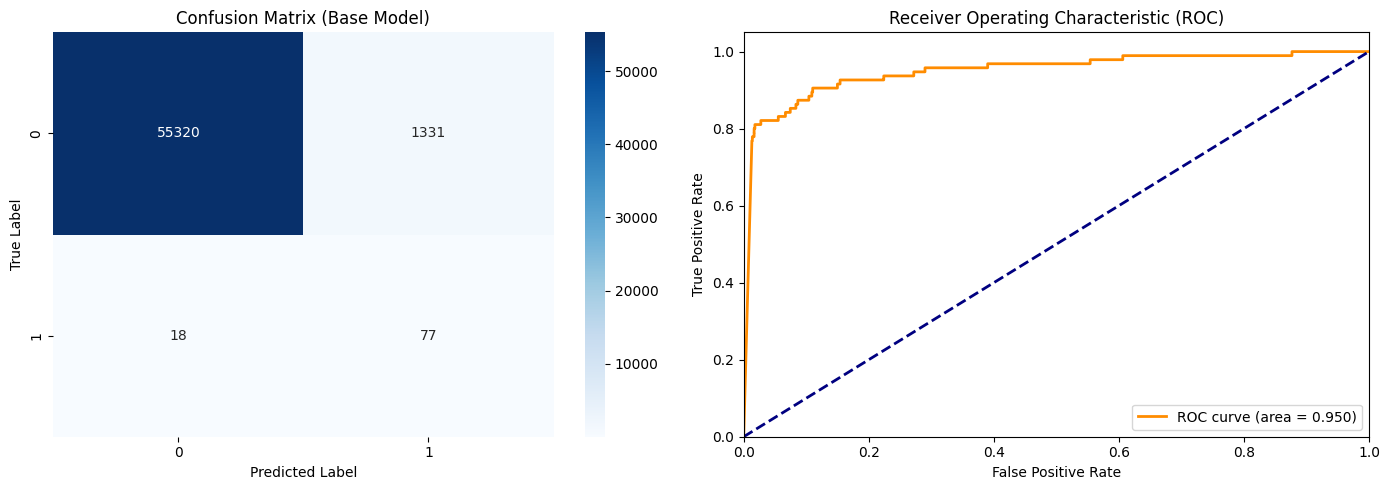

In [1883]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_fraud_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix (Base Model)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_fraud_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

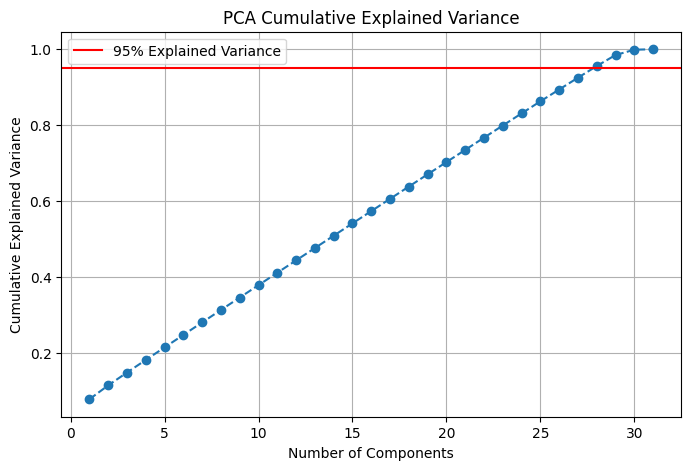

In [1884]:
pca = PCA()
pca.fit(X_fraud_train)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

In [1885]:
pca = PCA(n_components=28)

X_fraud_train_pca = pca.fit_transform(X_fraud_train)
X_fraud_test_pca = pca.transform(X_fraud_test)

print(f"Original features: {X_fraud_train.shape[1]}")
print(f"Reduced features (PCA): {X_fraud_train_pca.shape[1]}")

nb_pca = GaussianNB()
nb_pca.fit(X_fraud_train_pca, y_fraud_train)

y_pred_pca = nb_pca.predict(X_fraud_test_pca)
y_prob_pca = nb_pca.predict_proba(X_fraud_test_pca)[:, 1]


Original features: 31
Reduced features (PCA): 28


In [1886]:
print("=== PCA MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_fraud_test, y_pred_pca):.4f}\n")
print("Classification Report:")
print(classification_report(y_fraud_test, y_pred_pca, zero_division=0))

=== PCA MODEL EVALUATION ===
Accuracy: 0.9786

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.81      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.89      0.55     56746
weighted avg       1.00      0.98      0.99     56746



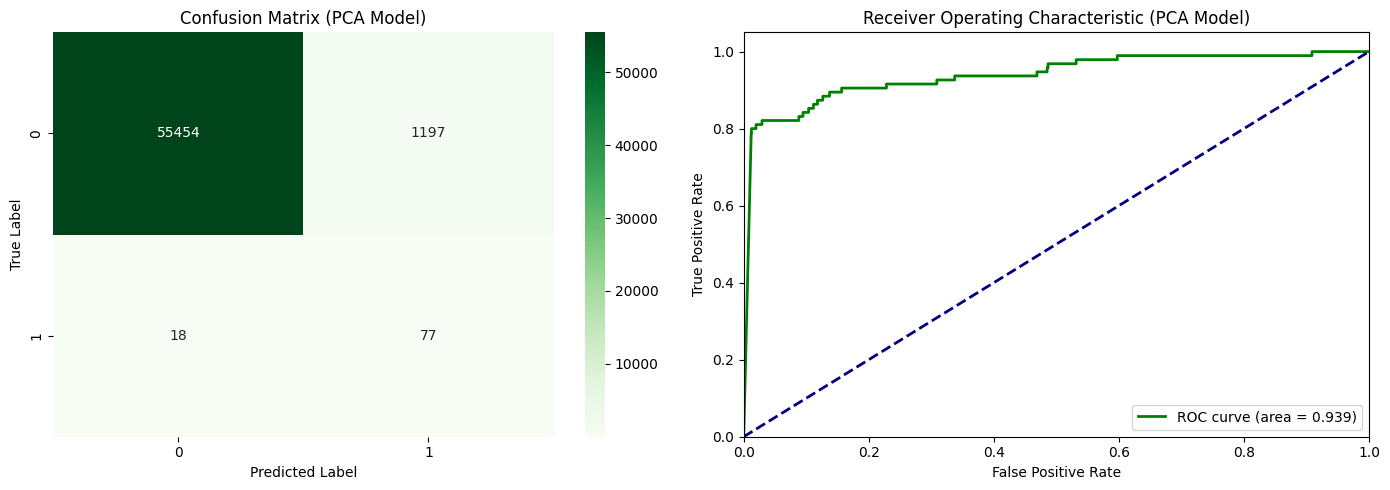

In [1887]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm_pca = confusion_matrix(y_fraud_test, y_pred_pca)
sns.heatmap(cm_pca, annot=True, fmt='d', cmap='Greens', ax=axes[0])
axes[0].set_title('Confusion Matrix (PCA Model)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve
fpr_pca, tpr_pca, thresholds_pca = roc_curve(y_fraud_test, y_prob_pca)
roc_auc_pca = auc(fpr_pca, tpr_pca)

axes[1].plot(fpr_pca, tpr_pca, color='green', lw=2, label=f'ROC curve (area = {roc_auc_pca:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (PCA Model)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## KNN Regressor

In [1888]:
knn = KNeighborsRegressor(n_neighbors=40, p=1)
knn.fit(X_crypto_train, y_crypto_train)
y_crypto_test_pred = knn.predict(X_crypto_test)

In [1889]:
test_r2 = r2_score(y_crypto_test, y_crypto_test_pred)
test_mae = mean_absolute_error(y_crypto_test, y_crypto_test_pred)
test_mse = mean_squared_error(y_crypto_test, y_crypto_test_pred)

print("=== FINAL TEST SET EVALUATION ===")
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE:      {test_mae:.4f}")
print(f"MSE:      {test_mse:.4f}")

=== FINAL TEST SET EVALUATION ===
R2 Score: 0.2058
MAE:      0.3938
MSE:      0.1968


In [1895]:
pca = PCA(n_components=3)
X_crypto_train = pca.fit_transform(X_crypto_train)
X_crypto_test = pca.transform(X_crypto_test)

In [1896]:
knn = KNeighborsRegressor(n_neighbors=40, p=1)
knn.fit(X_crypto_train, y_crypto_train)
y_crypto_test_pred = knn.predict(X_crypto_test)

In [1897]:
test_r2 = r2_score(y_crypto_test, y_crypto_test_pred)
test_mae = mean_absolute_error(y_crypto_test, y_crypto_test_pred)
test_mse = mean_squared_error(y_crypto_test, y_crypto_test_pred)

print("=== FINAL TEST SET EVALUATION ===")
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE:      {test_mae:.4f}")
print(f"MSE:      {test_mse:.4f}")

=== FINAL TEST SET EVALUATION ===
R2 Score: 0.1537
MAE:      0.4159
MSE:      0.2097


## Ensemble regressors

In [1893]:
print("Preparing stock data for modeling...")

sample_ticker = yahoo_data['Ticker'].iloc[0] 
print(f"Selected Ticker: {sample_ticker}")
stock_df = yahoo_data[yahoo_data['Ticker'] == sample_ticker].copy()

stock_df = stock_df.sort_values('Date')

# --- Feature Engineering ---
stock_df['MA_5'] = stock_df['Close'].rolling(window=5).mean()
stock_df['MA_10'] = stock_df['Close'].rolling(window=10).mean()
stock_df['Daily_Return'] = stock_df['Close'].pct_change()

delta = stock_df['Close'].diff()
gain = (delta.where(delta > 0, 0)).fillna(0)
loss = (-delta.where(delta < 0, 0)).fillna(0)
avg_gain = gain.ewm(com=14 - 1, min_periods=14).mean()
avg_loss = loss.ewm(com=14 - 1, min_periods=14).mean()
rs = avg_gain / avg_loss
stock_df['RSI_14'] = 100 - (100 / (1 + rs))

ema_12 = stock_df['Close'].ewm(span=12, adjust=False).mean()
ema_26 = stock_df['Close'].ewm(span=26, adjust=False).mean()
stock_df['MACD_Line'] = ema_12 - ema_26
stock_df['MACD_Signal'] = stock_df['MACD_Line'].ewm(span=9, adjust=False).mean()

stock_df['Return_Lag1'] = stock_df['Daily_Return'].shift(1)
stock_df['Return_Lag2'] = stock_df['Daily_Return'].shift(2)

stock_df['Volatility_10'] = stock_df['Daily_Return'].rolling(window=10).std()

stock_df['Target_Next_Return'] = stock_df['Close'].pct_change().shift(-1)

stock_df = stock_df.dropna()


features = [
    'Close', 'Volume', 
    'MA_5', 'MA_10', 'Daily_Return', 
    'RSI_14', 'MACD_Line', 'MACD_Signal',
    'Return_Lag1', 'Return_Lag2', 'Volatility_10'
]
X_stock = stock_df[features]
y_stock = stock_df['Target_Next_Return']

X_stock_train, X_stock_test, y_stock_train, y_stock_test = train_test_split(
    X_stock, y_stock, 
    test_size=0.2, 
    shuffle=False 
)

print(f"Training shapes: X={X_stock_train.shape}, y={y_stock_train.shape}")
print(f"Testing shapes: X={X_stock_test.shape}, y={y_stock_test.shape}")

Preparing stock data for modeling...
Selected Ticker: DIS
Training shapes: X=(10671, 11), y=(10671,)
Testing shapes: X=(2668, 11), y=(2668,)


Initializing Final Models with Explicit Best Parameters...
Training Final Random Forest...
Training Final XGBoost...

--- Final Model Evaluation (Out-of-Sample) ---
RANDOM FOREST:
  MSE: 0.000361
  MAE: 0.012826
  R2:  -0.0575

XGBOOST:
  MSE: 0.000342
  MAE: 0.012067
  R2:  -0.0001


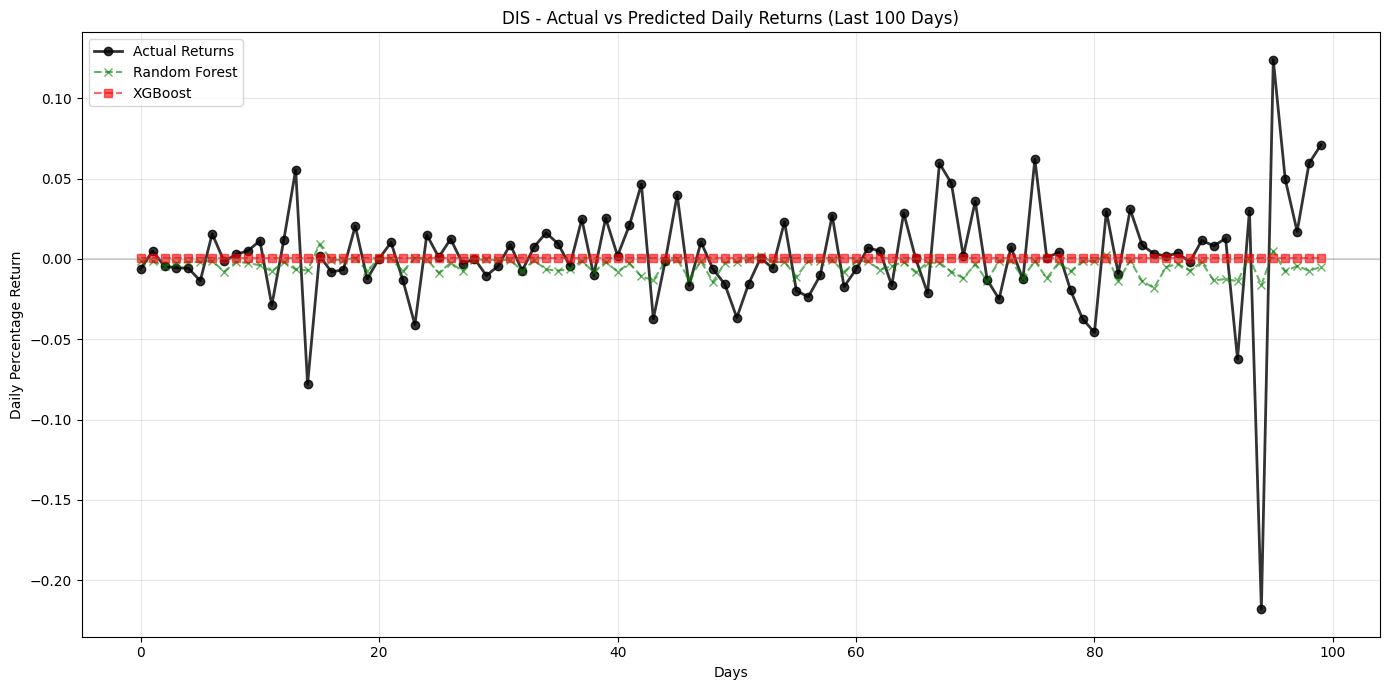

In [1894]:
print("Initializing Final Models with Explicit Best Parameters...")

# 1. Setup Final Random Forest (From Optuna Trial 58)
best_params_rf = {
    'n_estimators': 210, 
    'max_depth': 5, 
    'min_samples_split': 2, 
    'min_samples_leaf': 10,
    'random_state': 42,
    'n_jobs': -1
}
final_rf = RandomForestRegressor(**best_params_rf)

print("Training Final Random Forest...")
final_rf.fit(X_stock_train, y_stock_train)
rf_predictions = final_rf.predict(X_stock_test)

# 2. Setup Final XGBoost (From Optuna Trial 11)
best_params_xgb = {
    'n_estimators': 380, 
    'learning_rate': 0.27926006434202694, 
    'max_depth': 6, 
    'subsample': 0.5218003352159574, 
    'colsample_bytree': 0.7341882687722235, 
    'min_child_weight': 1, 
    'gamma': 1.0703765890972565, 
    'reg_alpha': 0.016006678280215965, 
    'reg_lambda': 8.214406800943035,
    'objective': 'reg:squarederror',
    'random_state': 42,
    'tree_method': 'hist',
    'device': 'cuda'
}
final_xgb = XGBRegressor(**best_params_xgb)

print("Training Final XGBoost...")
final_xgb.fit(X_stock_train, y_stock_train)
xgb_predictions = final_xgb.predict(X_stock_test)

# 3. Print Evaluation Metrics
print("\n--- Final Model Evaluation (Out-of-Sample) ---")
print("RANDOM FOREST:")
print(f"  MSE: {mean_squared_error(y_stock_test, rf_predictions):.6f}")
print(f"  MAE: {mean_absolute_error(y_stock_test, rf_predictions):.6f}")
print(f"  R2:  {r2_score(y_stock_test, rf_predictions):.4f}")

print("\nXGBOOST:")
print(f"  MSE: {mean_squared_error(y_stock_test, xgb_predictions):.6f}")
print(f"  MAE: {mean_absolute_error(y_stock_test, xgb_predictions):.6f}")
print(f"  R2:  {r2_score(y_stock_test, xgb_predictions):.4f}")

# 4. Plotting Actuals vs Both Models
plt.figure(figsize=(14, 7))
days_to_plot = 100 

plt.plot(y_stock_test.values[-days_to_plot:], label='Actual Returns', color='black', marker='o', alpha=0.8, linewidth=2)
plt.plot(rf_predictions[-days_to_plot:], label='Random Forest', color='green', marker='x', alpha=0.6, linestyle='--')
plt.plot(xgb_predictions[-days_to_plot:], label='XGBoost', color='red', marker='s', alpha=0.6, linestyle='--')

try:
    ticker_name = sample_ticker
except NameError:
    ticker_name = "Stock"

plt.title(f"{ticker_name} - Actual vs Predicted Daily Returns (Last 100 Days)")
plt.xlabel("Days")
plt.ylabel("Daily Percentage Return")
plt.axhline(0, color='gray', linestyle='-', alpha=0.3)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()